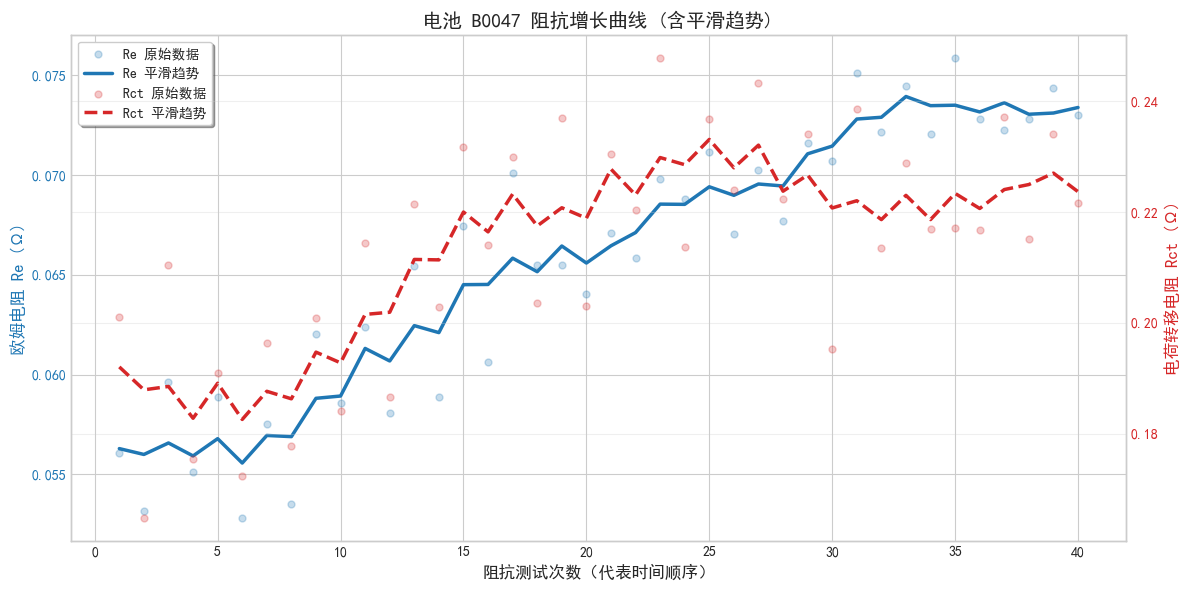

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ast
import numpy as np

# ==================== 1. 读取数据 ====================
meta_df = pd.read_csv('./data/metadata.csv')

# 仅保留阻抗数据
imp_df = meta_df[meta_df['type'] == 'impedance'].copy()

# ==================== 2. 清洗阻抗数据 ====================
# 自定义函数：处理字符串形式的复数，并提取实部
def clean_impedance(val):
    if pd.isna(val):
        return np.nan
    try:
        if isinstance(val, str):
            val = ast.literal_eval(val)
        if isinstance(val, complex):
            return val.real
        return float(val)
    except:
        return np.nan

imp_df['Re_clean'] = imp_df['Re'].apply(clean_impedance)
imp_df['Rct_clean'] = imp_df['Rct'].apply(clean_impedance)

# 剔除异常值（电池阻抗一般在 0.01 到 1 欧姆之间）
imp_df = imp_df[(imp_df['Re_clean'] > 0.01) & (imp_df['Re_clean'] < 1.0)]
imp_df = imp_df[(imp_df['Rct_clean'] > 0.01) & (imp_df['Rct_clean'] < 1.0)]

# 按电池编号和测试序号（uid）排序，确保画图顺序正确
imp_df = imp_df.sort_values(by=['battery_id', 'uid'])
# 为每块电池生成独立的阻抗测试序号（1, 2, 3...）
imp_df['test_seq'] = imp_df.groupby('battery_id').cumcount() + 1

# ==================== 3. 提取目标电池数据并平滑 ====================
# 选择目标电池（这里选 B0047）
battery_id = 'B0047'
battery_data = imp_df[imp_df['battery_id'] == battery_id].copy()

# 滑动平均平滑处理（窗口大小设为5，center=True表示以当前点为中心取前后各2个点）
# min_periods=1 保证首尾两端也能计算出平滑值，不会产生空值
window_size = 5
battery_data['Re_smooth'] = battery_data['Re_clean'].rolling(window=window_size, center=True, min_periods=1).mean()
battery_data['Rct_smooth'] = battery_data['Rct_clean'].rolling(window=window_size, center=True, min_periods=1).mean()

# ==================== 4. 绘制双Y轴曲线 ====================
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用 SimHei，Mac 请改为 ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

fig, ax1 = plt.subplots(figsize=(12, 6))

# --- 左轴：欧姆电阻 Re (蓝色) ---
color_re = '#1f77b4'
# 画原始数据散点（半透明，保留真实波动）
ax1.scatter(battery_data['test_seq'], battery_data['Re_clean'], 
            color=color_re, alpha=0.25, s=25, label='Re 原始数据')
# 画平滑趋势线
ax1.plot(battery_data['test_seq'], battery_data['Re_smooth'], 
         color=color_re, linewidth=2.5, label='Re 平滑趋势')
ax1.set_xlabel('阻抗测试次数（代表时间顺序）', fontsize=12)
ax1.set_ylabel('欧姆电阻 Re (Ω)', color=color_re, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_re)

# --- 右轴：电荷转移电阻 Rct (红色) ---
ax2 = ax1.twinx()  # 创建共享X轴的第二个Y轴
color_rct = '#d62728'
# 画原始数据散点（半透明）
ax2.scatter(battery_data['test_seq'], battery_data['Rct_clean'], 
            color=color_rct, alpha=0.25, s=25, label='Rct 原始数据')
# 画平滑趋势线（用虚线区分）
ax2.plot(battery_data['test_seq'], battery_data['Rct_smooth'], 
         color=color_rct, linewidth=2.5, linestyle='--', label='Rct 平滑趋势')
ax2.set_ylabel('电荷转移电阻 Rct (Ω)', color=color_rct, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_rct)

# --- 合并图例并美化 ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10, frameon=True, shadow=True)

plt.title(f'电池 {battery_id} 阻抗增长曲线 (含平滑趋势)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()